# Chapter 10 · Real data II: a multi-pass fit

Fit the June 7 and June 8 morning passes, from two DSN complexes 11 hours apart, with the parameters real data need, starting from the simulated week's solution, and read the result against the flight reconstruction.

[Chapter 9](09_real_dsn_data.ipynb) turned three DSN passes into edited, weighted measurements and found the ranging offset by a constant per station. This chapter fits two of them with a batch square-root information filter (`SRIFB`) and a state that real data need: position and velocity, an SRP scale factor, stochastic accelerations, and one range bias per station. The a priori is the solution of the simulated week ([chapter 6](06_first_od_solution.ipynb)), the way a navigation team starts from its last solution. The third pass, on the evening of June 8, stays out: [chapter 11](11_real_data_prediction.ipynb) predicts it.

**In this chapter**

1. **The a priori:** the simulated week's solution on June 7, and why its covariance must be inflated
2. **The estimated state:** an SRP scale factor, stochastic accelerations, and a range bias per station
3. **The fit:** `SRIFB` from the a priori, and how it converged
4. **Results:** residuals, parameters, and the trajectory against the flight reconstruction
5. **Why the range biases need a realistic a priori:** the information matrix, and the same fit with loose biases

**Time:** ~15 min · **Prereqs:** [8. Estimating parameters](08_estimating_more.ipynb), [9. Real data I](09_real_dsn_data.ipynb) · **Uses:** `outputs/06_first_od_solution/solution.json`, `outputs/09_real_dsn_data/editing.json` · **Next:** [11. Real data III: is the solution any good?](11_real_data_prediction.ipynb)

> **Preview.** Chapters 9–11 are a first draft.

## Setup

The scenario, the real-data helpers of [chapter 9](09_real_dsn_data.ipynb) and the outputs of chapters 6 and 9 (`python prepare.py 10` generates them). `real_tracking()` reads the two passes as chapter 9 did, and `load_editing()` applies chapter 9's outlier flags and data weights to them.

In [1]:
from pathlib import Path

import numpy as np
import scarabaeus as scb

from scenario import (
    APRIORI_INFLATION,
    ARC_END_UTC,
    BIAS_SIGMA_M,
    FIT_PASSES,
    J2000,
    PFOGM_BATCH_S,
    PFOGM_TAU_S,
    PREDICTION_DAYS,
    REAL_DATA_KERNELS,
    area,
    cr,
    full_covariance,
    km,
    load_editing,
    mass,
    orex_flight,
    output_folder,
    planets,
    range_unit_m,
    real_data_fit,
    real_stations,
    real_tracking,
    reference_real,
    sec,
    simulated_apriori,
    sun,
)

out = output_folder("10_real_data_fit")
scb.SpiceManager.load_kernel_from_mkfile(REAL_DATA_KERNELS)

batch_file = Path("outputs/06_first_od_solution/solution.json")  # produced by chapter 6
editing_file = Path("outputs/09_real_dsn_data/editing.json")  # produced by chapter 9
if not (batch_file.exists() and editing_file.exists()):
    raise FileNotFoundError("Run chapters 6 and 9 first, or: python prepare.py 10")

In [2]:
%%capture
# hide the progress output of the filters and measurement models

tracking = load_editing(real_tracking(FIT_PASSES), editing_file)
ru_m = {leaf.dataset_name[:6]: range_unit_m(leaf) for leaf in tracking.leaves if "ranging" in leaf.dataset_name}

## 1. The a priori

Operations start a fit from the last solution, mapped to the start of the new arc. Here the last solution is chapter 6's batch fit of the simulated week. It covers June 1–8, so it has an estimate on June 7 at 17:30 UTC, an hour before the first real pass: `simulated_apriori()` reads it, state and covariance, from chapter 6's `solution.json`. Strictly, the simulated tracking runs to June 8 00:00, so the batch estimate at 17:30 has seen six hours of simulated data that overlap the June 7 pass. They are simulated, independent of the real data, so no measurement is used twice.

How far is it from the flight reconstruction, and does its covariance know?

In [3]:
t0, x0, P_sim = simulated_apriori()
print("a-priori epoch:", scb.SpiceManager.et2utc(t0)[:19], "UTC")


def los_axis(t):
    """Unit vector from Earth to the spacecraft (the flight reconstruction) at TDB seconds t."""
    r = orex_flight.get_state(scb.EpochArray([t], sys="TDB")[0], reference_frame="J2000", origin="EARTH")
    r = r.quantity.values[:3]
    return r / np.linalg.norm(r)


x_flight = orex_flight.get_state(scb.EpochArray([t0], sys="TDB")[0], reference_frame="J2000", origin="SUN")
dx = x0 - x_flight.quantity.values
u = los_axis(t0)
print(f"simulated-week estimate − OD044: {np.linalg.norm(dx[:3]):.2f} km, {np.linalg.norm(dx[3:]) * 1e6:.2f} mm/s; "
      f"along the line of sight {dx[:3] @ u * 1e3:+.0f} m, {dx[3:] @ u * 1e6:+.2f} mm/s")
print(f"its 1σ: {np.trace(P_sim[:3, :3]) ** 0.5:.2f} km, {np.trace(P_sim[3:, 3:]) ** 0.5 * 1e6:.2f} mm/s (RSS); "
      f"along the line of sight {(u @ P_sim[:3, :3] @ u) ** 0.5 * 1e3:.2f} m, {(u @ P_sim[3:, 3:] @ u) ** 0.5 * 1e6:.3f} mm/s")

a-priori epoch: 2018-06-07T17:30:00 UTC
simulated-week estimate − OD044: 0.85 km, 1.45 mm/s; along the line of sight -96 m, -0.51 mm/s
its 1σ: 1.68 km, 1.54 mm/s (RSS); along the line of sight 0.35 m, 0.074 mm/s


In total, the estimate is within its covariance: 0.85 km against a 1.7 km RSS σ. Along the line of sight it is not: the simulated week determined the line-of-sight position to 0.35 m, and the estimate is 96 m from the reconstruction there, about 270σ.

The covariance is right about the simulation. The simulated measurements were generated from a truth that is not the real spacecraft: it started from the flight state on June 1 and drifted from the flight reconstruction by up to a few hundred meters in a week ([chapter 2](02_truth_dynamics.ipynb)). The formal covariance of a fit knows only the errors it was told about. Taking a solution as the a priori for new data, a navigation team inflates its covariance to cover what it does not model. Here: 1 km and 1 mm/s per axis are added (`APRIORI_INFLATION` in `scenario.py`), which keeps the shape of the simulated-week covariance in the plane of the sky and opens the line of sight to about 1 km and 1 mm/s:

In [4]:
P_apriori = P_sim + np.diag([APRIORI_INFLATION[0] ** 2] * 3 + [APRIORI_INFLATION[1] ** 2] * 3)
sigma_los = (u @ P_apriori[:3, :3] @ u) ** 0.5
print(f"inflated 1σ along the line of sight: {sigma_los * 1e3:.0f} m, {(u @ P_apriori[3:, 3:] @ u) ** 0.5 * 1e6:.2f} mm/s; "
      f"the {dx[:3] @ u * 1e3:+.0f} m error is {abs(dx[:3] @ u) / sigma_los:.2f}σ")

inflated 1σ along the line of sight: 1000 m, 1.00 mm/s; the -96 m error is 0.10σ


## 2. The estimated state

| Component | Size | Owner | Kind | A priori | 1σ |
|---|---|---|---|---|---|
| `position`, `velocity` | 6 | reference spacecraft | dynamic | the simulated week on June 7, 17:30 | its covariance + 1 km, 1 mm/s per axis |
| `a_pfogm` | 3 per batch | reference spacecraft | dynamic | 0 | 5 × 10⁻¹² km/s² (5 nm/s²) per axis |
| `eta_srp` | 1 | reference spacecraft | static | 1 | 0.5 |
| `range_bias_RU_DSS65` | 1 | DSS-65 | static | 0 RU | 100 m one-way (about 710 RU) |
| `range_bias_RU_DSS35` | 1 | DSS-35 | static | 0 RU | 5 m one-way (about 35 RU) |

- **SRP scale factor.** As in [chapter 8](08_estimating_more.ipynb): the cannonball area and reflectivity of the scenario are rough values, and η_SRP scales the SRP acceleration.
- **Stochastic accelerations.** A force model is never complete: the cannonball is a box with solar panels, and thermal re-radiation, outgassing and attitude-control leaks push the spacecraft too. Piecewise first-order Gauss–Markov accelerations (PFOGM) give the filter room for them: the arc is cut into 9-hour batches, one per pass, and each batch carries a 3-axis acceleration that decays with a correlation time of one day. In a batch filter, the batch accelerations are estimated parameters, each with its a priori σ: 5 nm/s², a quarter of the SRP acceleration (below). The batches continue over the three days after the data that chapter 11 predicts: no data constrain those, so they carry their full a priori into the prediction covariance. This replaces the process noise of [chapter 7](07_sequential_filtering.ipynb), which a sequential filter adds between measurements.
- **Range biases, one per station.** Chapter 9 found the ranging offset by a constant per station: −9 m at DSS-35, +52 m at DSS-65. A bias per station absorbs it, and its a priori says what is known about it. DSS-35: 5 m, the systematics of the transponder delay, which was estimated with DSS-35 tracking. DSS-65: 100 m, since its +52 m offset is not explained. Each bias is a parameter owned by its `GroundStation`, so it applies to every ranging pass of that station (section 5 shows why the a priori matters).

A separate spacecraft object, `reference_real` (SPICE ID `-64002`), carries the reference trajectory of this fit, so its SPK never shadows the flight reconstruction or the reference of the simulated chapters.

In [5]:
arc = scb.EpochArray(np.arange(t0, scb.SpiceManager.utc2et(ARC_END_UTC) + 1.0, 60.0), sys="TDB")
n_batches = int(np.ceil((arc[-1].et - t0 + PREDICTION_DAYS * 86400.0) / PFOGM_BATCH_S))
PFOGM_SIGMA = 5e-12  # km/s^2

r_sun = np.linalg.norm(x0[:3]) / 1.495978707e8  # AU
a_srp = 4.56e-6 * float(cr.values) * float(area.convert_to(km**2).values) * 1e6 / float(mass.values) / r_sun**2 * 1e-3
print(f"arc: {scb.SpiceManager.et2utc(arc[0].et)[:16]} to {scb.SpiceManager.et2utc(arc[-1].et)[:16]} UTC; "
      f"{n_batches} PFOGM batches of {PFOGM_BATCH_S / 3600:.0f} h, to {PREDICTION_DAYS} days after the arc")
print(f"SRP acceleration at {r_sun:.2f} AU: {a_srp:.2e} km/s^2; the PFOGM σ is {PFOGM_SIGMA / a_srp:.0%} of it")

arc: 2018-06-07T17:30 to 2018-06-08T11:45 UTC; 11 PFOGM batches of 9 h, to 3 days after the arc
SRP acceleration at 1.31 AU: 2.34e-11 km/s^2; the PFOGM σ is 21% of it


In [6]:
state = (
    scb.StateDefinition()
    .position(reference_real, scb.ArrayWFrame(scb.ArrayWUnits(x0[:3], km), J2000))
    .velocity(reference_real, scb.ArrayWFrame(scb.ArrayWUnits(x0[3:], km / sec), J2000))
    .param("a_pfogm", reference_real, scb.ArrayWFrame(scb.ArrayWUnits(np.zeros(3 * n_batches), km / sec**2), J2000),
           estimation="estimated", dynamics="dynamic")
    .param("eta_srp", reference_real, scb.ArrayWFrame(scb.ArrayWUnits([1.0], None), J2000),
           estimation="estimated", dynamics="static")
)
for dss, station in real_stations.items():
    state = state.param(f"range_bias_RU_{dss.replace('-', '')}", station,
                        scb.ArrayWFrame(scb.ArrayWUnits([0.0], None), J2000), estimation="estimated", dynamics="static")

# a-priori covariance: the inflated simulated-week block, then the parameters' variances
sigma_params = [PFOGM_SIGMA] * (3 * n_batches) + [0.5] + [BIAS_SIGMA_M[dss] / ru_m[dss] for dss in real_stations]
units = [km] * 3 + [km / sec] * 3 + [km / sec**2] * (3 * n_batches) + [None] * 3
P0 = np.zeros((6 + len(sigma_params),) * 2)
P0[:6, :6] = P_apriori
P0[6:, 6:] = np.diag(np.square(sigma_params))
print(f"{P0.shape[0]} estimated elements; range-bias a priori: "
      + ", ".join(f"{dss} {BIAS_SIGMA_M[dss]:.0f} m = {BIAS_SIGMA_M[dss] / ru_m[dss]:.0f} RU" for dss in real_stations))

42 estimated elements; range-bias a priori: DSS-65 100 m = 708 RU, DSS-35 5 m = 35 RU


`CovarianceMatrix` takes the a priori as standard deviations with their units and, for a correlated block like the simulated week's, the correlation coefficients; `full_covariance()` in `scenario.py` does that conversion. The force model adds the PFOGM accelerations to the dynamics of the earlier chapters:

In [7]:
forces = scb.ForceModelTranslation(
    primary_body=reference_real,
    third_bodies=planets,
    cannonball_SRP=True,
    piecewise_first_order_gauss_markov=True,
    pfogm_batch_length=PFOGM_BATCH_S,
    pfogm_n_batches=n_batches,
    pfogm_beta=np.full(3, 1 / PFOGM_TAU_S),
    t0=arc[0],
)
propagator = scb.Propagator(
    primary_body=reference_real,
    state_vector=scb.StateArray(epoch=arc[0], origin=sun, state=state),
    tspan=arc,
    force_models=forces,
    display_progress=False,
)
settings = scb.FilterSettings(initial_covariance=full_covariance(P0, units, arc[0]))

## 3. The fit

The filter call is the one from [chapter 6](06_first_od_solution.ipynb). The cost test stops it, with a 1% threshold as in the real-data chapters: on a weakly observable arc, the deviation test would keep iterating on directions the data barely see.

In [8]:
%%capture
# hide the progress output of the filters and measurement models

srifb = scb.SRIFB(propagator=propagator, measurements=tracking, settings=settings,
                  traj_name="reference.bsp", traj_dir=str(out))
solution, n_iterations, converged = srifb.fit(traj_name="reference.bsp", traj_dir=str(out),
                                              convergence_threshold_cost=1e-2)
solution.save(out / "solution.json")

converged: True, after 2 iterations


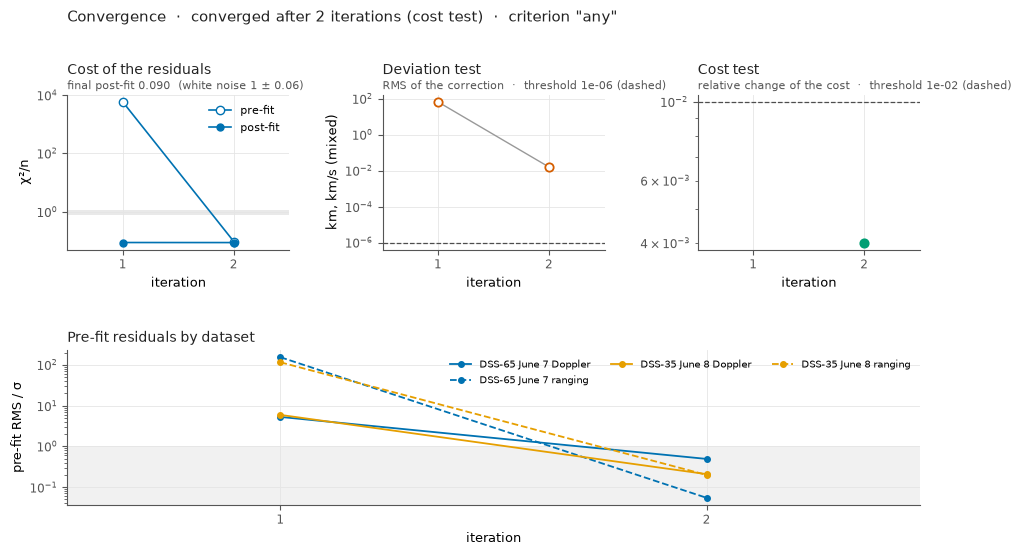

In [9]:
from plotting_prototype import plot_convergence

print(f"converged: {converged}, after {n_iterations} iterations")
plot_convergence(out / "solution.json");

The first pre-fit cost measures the a-priori error: about a kilometer, seen by ranging weighted at 1 m. One iteration removes it; the second confirms it. `real_data_fit()` in `scenario.py` repeats sections 2 and 3 in one call; chapter 11 uses it.

## 4. Results

### Residuals

The post-fit residuals, with a running median (`trend=True`) to show what χ²/n averages away:

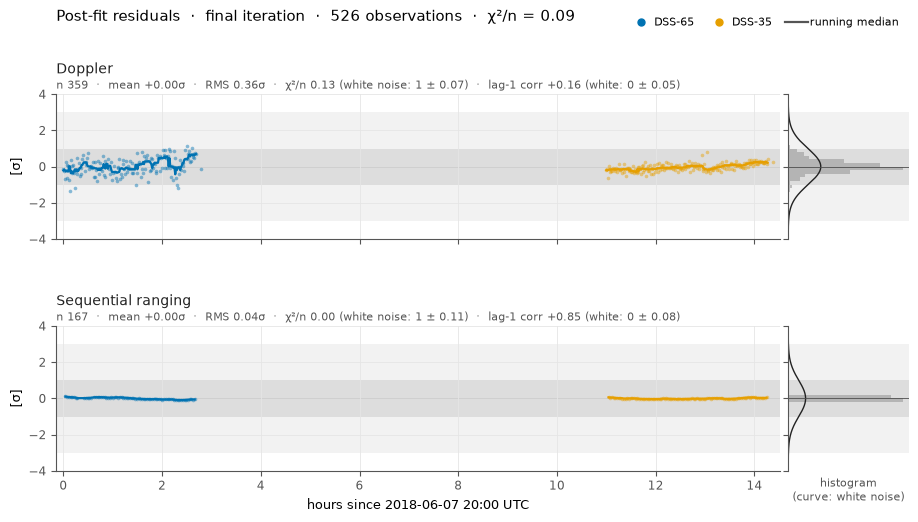

In [10]:
from plotting_prototype import plot_residuals

plot_residuals(out / "solution.json", trend=True);

Both data types are well inside their weights: χ²/n is far below 1, as chapter 9's weights intend (they cover model errors the fit does not see; the noise is several times smaller). The ranging residuals keep the slow drift of chapter 9, centimeters over a pass, which no constant bias can remove.

### Parameters

The estimates at the start of the arc. `propagate_state_covariance` maps the solution and its covariance to any epoch:

In [11]:
%%capture
# hide the progress output of the filters and measurement models

t_last = max(float(np.max(leaf.observed_meas.meas_time_et.times.values)) for leaf in tracking.leaves)
(state_0, P_0), (state_end, P_end) = solution.propagate_state_covariance(
    scb.EpochArray([t0, t_last], sys="TDB"), use_smoothed=False, use_all_data=True)
x_hat = np.asarray(state_0.values0.values, dtype=float).ravel()

In [12]:
i_eta = 6 + 3 * n_batches
print(f"eta_srp = {x_hat[i_eta]:.3f} ± {P_0[i_eta, i_eta] ** 0.5:.3f} (a priori 1 ± 0.5)")
for k, dss in enumerate(real_stations):
    i = i_eta + 1 + k
    b, s = x_hat[i], P_0[i, i] ** 0.5
    print(f"range bias {dss}: {b:+7.1f} ± {s:5.1f} RU = {b * ru_m[dss]:+6.1f} ± {s * ru_m[dss]:4.1f} m one-way "
          f"(a priori 0 ± {BIAS_SIGMA_M[dss]:.0f} m)")
i_a = slice(6, 6 + 3 * n_batches)
a_sigma = np.sqrt(np.diag(P_0)[i_a]).reshape(-1, 3) / PFOGM_SIGMA
print(f"PFOGM batches with data: σ/σ_prior {a_sigma[:2].min():.2f}–{a_sigma[:2].max():.2f}; "
      f"largest |a| {np.abs(x_hat[i_a]).reshape(-1, 3)[:2].max() * 1e12:.1f} nm/s^2")

eta_srp = 1.090 ± 0.167 (a priori 1 ± 0.5)
range bias DSS-65:  +434.9 ±  35.8 RU =  +61.5 ±  5.1 m one-way (a priori 0 ± 100 m)
range bias DSS-35:    -1.1 ±  35.3 RU =   -0.2 ±  5.0 m one-way (a priori 0 ± 5 m)
PFOGM batches with data: σ/σ_prior 0.87–0.96; largest |a| 0.9 nm/s^2


- **η_SRP** moves to about 1.09 and its σ shrinks from 0.5 to about 0.17: two passes see the SRP acceleration only weakly.
- **The range biases.** DSS-35 stays at its a priori, 0 ± 5 m: nothing in the data can move it (section 5). DSS-65 lands at about +61 m: its +52 m offset against the reconstruction, plus the 9 m by which the fit has moved the line-of-sight position to match DSS-35 (below).
- **The stochastic accelerations** stay near zero with σ close to their a priori: two passes cannot resolve 5 nm/s² accelerations over 9-hour batches. They still matter, in the covariance of the prediction (chapter 11).

`plot_parameter_learning` shows the same for every state element at the start of the arc, the line of sight and the plane of sky separately: how much the data shrank each σ (left), how far each estimate moved in units of its a-priori σ (middle), and the values (right):

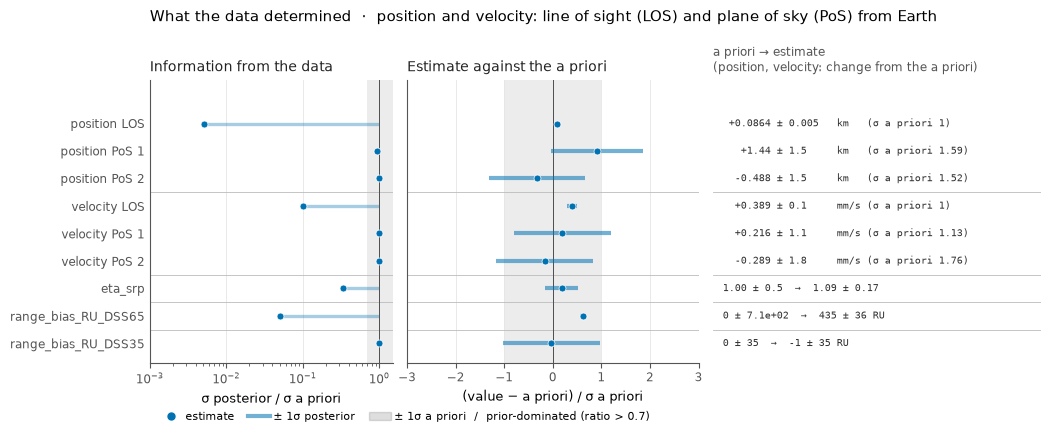

In [13]:
from plotting_prototype import plot_parameter_learning

plot_parameter_learning(out / "solution.json",
                        components=["position", "velocity", "eta_srp", "range_bias_RU_DSS65", "range_bias_RU_DSS35"]);

The line-of-sight position and velocity are determined far below their a priori; the plane of sky is not: two passes from Earth constrain it only through the dynamics and the Earth's rotation. The DSS-35 bias is prior-dominated; the DSS-65 bias is not.

### Against the flight reconstruction

The flight reconstruction (OD044) was built by the navigation team from far more tracking than two passes. It is a reference, not the truth, but differences against it of more than a few meters along the line of sight belong to this fit. `state_errors` and `plot_consistency` ([chapter 6](06_first_od_solution.ipynb)) compare the estimate with it every 10 minutes over the arc:

In [14]:
%%capture
# hide the progress output of the filters and measurement models

from plotting_prototype import plot_consistency, state_errors

grid = scb.EpochArray(np.arange(t0, arc[-1].et, 600.0), sys="TDB")
errors = state_errors(solution, orex_flight, grid, frame="LOS", use_smoothed=False, use_all_data=True)

at the last measurement: line of sight -9.1 m, plane of sky 2.35 km


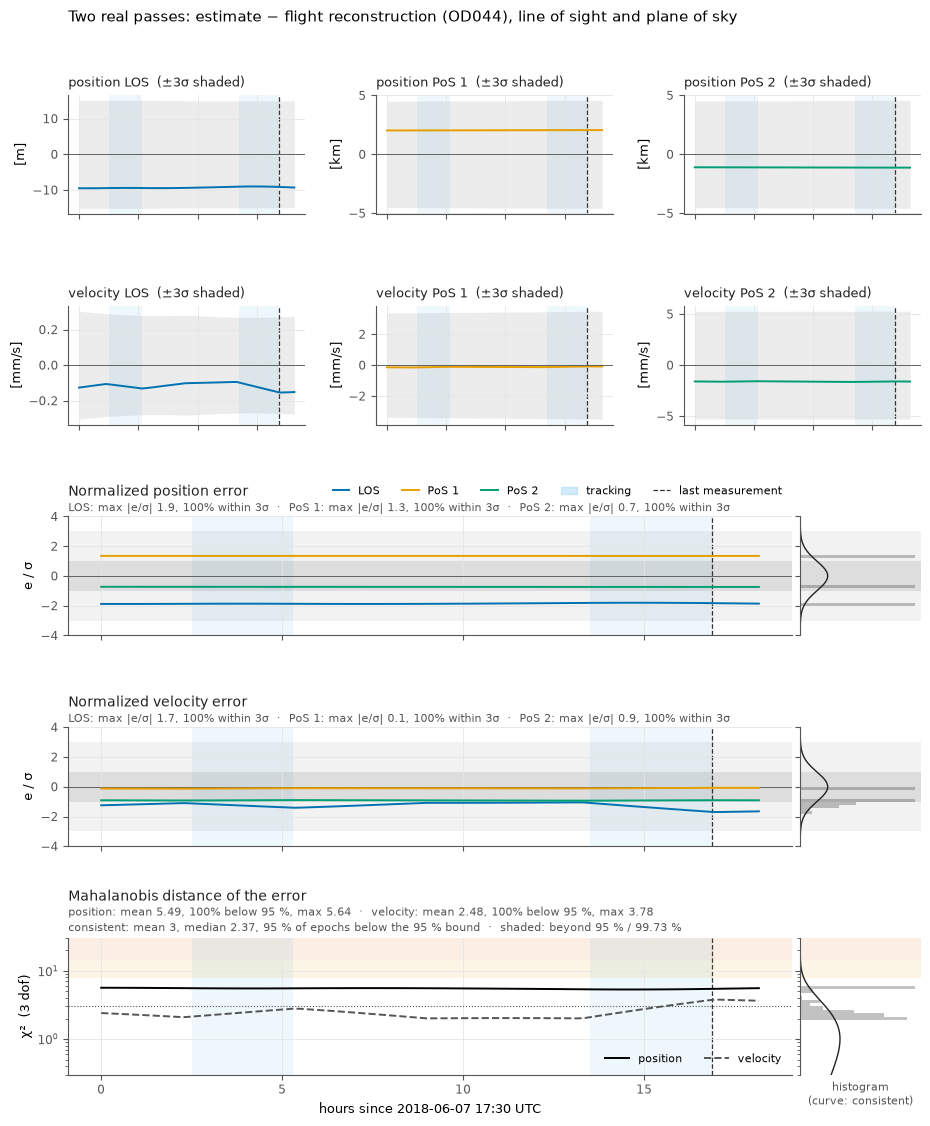

In [15]:
e, P = errors["error"], errors["covariance"]
print(f"at the last measurement: line of sight {np.interp(t_last, errors['t'], e[:, 0]) * 1e3:+.1f} m, "
      f"plane of sky {np.hypot(e[-1, 1], e[-1, 2]):.2f} km")
plot_consistency(errors, title="Two real passes: estimate − flight reconstruction (OD044), line of sight and plane of sky");

- **Line of sight:** the estimate sits about 9 m below the reconstruction throughout, inside its 3σ. That is the DSS-35 ranging offset of chapter 9: with the DSS-35 bias held at 0 ± 5 m, the fit moves the position to match the DSS-35 ranges, and the DSS-65 bias takes up the rest. The line-of-sight velocity agrees to a fraction of a mm/s.
- **Plane of sky:** kilometers, inside its σ, which is close to the a priori: two passes cannot determine it.

The line-of-sight position is only as good as the calibration behind the DSS-35 bias. Section 5 shows why.

## 5. Why the range biases need a realistic a priori

Over a few hours the line of sight barely turns, so a constant range bias and a shift of the spacecraft along the line of sight change every ranging measurement of a station the same way. The data measure their sum, not each one.

`observability_test()` returns the information matrix of the fit, Λ = Σ (HΦ)ᵀ R⁻¹ (HΦ): the information the measurements carry about each combination of state elements, before the a priori is added. Scaled by the a-priori σ, its eigenvalues say in how many independent directions the data outweigh the a priori:

In [16]:
%%capture
# hide the progress output of the filters and measurement models

information, _ = srifb.observability_test()

In [17]:
sigma_0 = np.sqrt(np.diag(P0))
eigenvalues = np.linalg.eigvalsh(information * np.outer(sigma_0, sigma_0))
print(f"the data outweigh the a priori in {np.sum(eigenvalues > 1)} of {len(eigenvalues)} directions")


def los_bias_correlation(P, dss, t):
    """Correlation of the line-of-sight position and the range bias of station dss in the covariance P."""
    i = i_eta + 1 + list(real_stations).index(dss)
    u_t = los_axis(t)
    return (u_t @ P[:3, i]) / ((u_t @ P[:3, :3] @ u_t) * P[i, i]) ** 0.5


print("after the fit, correlation of the line-of-sight position with the range bias of "
      + ", ".join(f"{dss}: {los_bias_correlation(P_end, dss, t_last):+.4f}" for dss in real_stations))

the data outweigh the a priori in 5 of 42 directions
after the fit, correlation of the line-of-sight position with the range bias of DSS-65: -0.9880, DSS-35: -0.9997


Two passes of Doppler and ranging determine only a handful of the 42 directions; the a priori sets the rest (the plane of sky over the whole arc, the stochastic accelerations, and the common part of the biases). After the fit, the line-of-sight position is correlated with each bias at −0.99 or beyond: the data pinned their sum. Two stations help only through what they do not share: the difference of their biases is tied to the trajectory between the passes, but their common part is not measured. The a priori sets it, here the 5 m of DSS-35. With both biases loose, the line-of-sight position has nothing to hold on to. The same fit with 100 m on both, using `real_data_fit()`:

In [18]:
%%capture
# hide the progress output of the filters and measurement models

_, solution_loose = real_data_fit(tracking, bias_sigma_m={"DSS-65": 100.0, "DSS-35": 100.0}, traj_dir=out, tag="loose")
(_, P_loose), = solution_loose.propagate_state_covariance(scb.EpochArray([t_last], sys="TDB"),
                                                          use_smoothed=False, use_all_data=True)
errors_loose = state_errors(solution_loose, orex_flight, scb.EpochArray([t_last], sys="TDB"), frame="LOS",
                            use_smoothed=False, use_all_data=True)

In [19]:
u_end = los_axis(t_last)
for label, P_k, e_k in [("DSS-35 bias 5 m", P_end, np.interp(t_last, errors["t"], e[:, 0])),
                        ("both biases 100 m", P_loose, errors_loose["error"][0, 0])]:
    print(f"{label:18s} line-of-sight position at the last measurement: {e_k * 1e3:+6.1f} m, "
          f"1σ {(u_end @ P_k[:3, :3] @ u_end) ** 0.5 * 1e3:5.1f} m")

DSS-35 bias 5 m    line-of-sight position at the last measurement:   -9.1 m, 1σ   5.0 m
both biases 100 m  line-of-sight position at the last measurement:  +20.9 m, 1σ  70.5 m


With both biases loose, the line-of-sight σ grows from about 5 m to about 70 m: the fit can no longer tell where along the line of sight the spacecraft is, only that it agrees with both stations up to a common bias. The residuals are the same in both fits. A loose bias is not a cautious choice: it hands the line-of-sight position to the a priori of the bias.

## Takeaways

- A previous solution is the a priori of the next fit, but its formal covariance knows only the errors it was told about: the simulated week's 0.35 m line-of-sight σ hid a 96 m difference from the real trajectory. Inflate it before use.
- Real data need more than position and velocity: an SRP scale factor, stochastic accelerations for the force-model errors, and a range bias per station for the calibration errors.
- Two passes determine the line-of-sight position and velocity; the plane of sky stays near its a priori, and the stochastic accelerations at theirs, until the prediction (chapter 11).
- A range bias and the line-of-sight position are measured only as a sum. The a priori of the bias decides the line-of-sight position: the DSS-35 calibration (5 m) puts the estimate 9 m from the reconstruction with a 5 m σ; loose biases give a 70 m σ with the same residuals.

<details>
<summary><b>API used in this chapter</b></summary>

| Concept | Scarabaeus API |
|---|---|
| Stochastic accelerations | `ForceModelTranslation(piecewise_first_order_gauss_markov=True, pfogm_batch_length=..., pfogm_n_batches=..., pfogm_beta=..., t0=...)`, state component `a_pfogm` |
| Range bias per station | `StateDefinition.param("range_bias_RU_<tag>", station, ...)`: applies to every ranging pass of that station |
| Correlated a priori | `CovarianceMatrix(sigmas, epoch, from_list=True, corr_factors=[...])` (`full_covariance()` in `scenario.py`) |
| Solution at any epoch | `SolutionOD.propagate_state_covariance(epochs, use_smoothed=False, use_all_data=True)` |
| Information matrix | `filter.observability_test()` → (Λ, observability matrix) |
| The whole fit in one call | `real_data_fit(tracking, pfogm_sigma=..., bias_sigma_m=...)` in `scenario.py` |
| Convergence, residuals, parameters, consistency | `plot_convergence`, `plot_residuals(..., trend=True)`, `plot_parameter_learning`, `plot_consistency(state_errors(...))` (prototypes) |

</details>

**Next:** [11. Real data III: is the solution any good?](11_real_data_prediction.ipynb) tests this solution by what it predicts: three days ahead against the reconstruction, and the evening DSS-65 pass against its measurements.